# Negative-Sobolev residual norms on Kolmogorov flow

Notebook 07 showed that measuring the Darcy residual in $H^{-1}$ instead of $L^2$ helps far more than changing the optimizer. Does the idea carry over to Navier–Stokes? Here the Crank–Nicolson residual $r$ of the vorticity equation is measured in the relative norm

$$
\mathcal L_{\rm pde} = \frac{\|r\|_{-s}}{\|f\|_{-s}}, \qquad \|r\|_{-s}^2 = \sum_t \sum_{k \in \mathbb Z^2} (1 + |k|^2)^{-s}\,|\hat r(k, t)|^2,
$$

on the $2\pi$-torus, with $s = 0$ ($L^2$), $s = 1$ ($H^{-1}$) and $s = 1/2$ ($H^{-1/2}$). The Crank–Nicolson system is square, so all three losses have the **same exact minimizer** and the same floor: only the conditioning of the optimization changes. Implemented as `cfg["residual_sobolev"] = s` in `pino_bench.Kolmogorov`.

**Why $H^{-1/2}$ might fit.** For the vorticity error $e$, the energy identity $\tfrac12 \tfrac{d}{dt}\|e\|^2 + 
u\|
abla e\|^2 = -(v\cdot
abla w, e) + (r, e)$ can be closed with $r \in H^{-1}$ (absorbing $\|
abla e\|$ by viscosity, constant $1/
u = Re$), with $r \in L^2$ (no viscosity, Re-independent constant), or with $r \in H^{-1/2}$ in between (constant $
u^{-1/3}$). At high Re advection dominates, which favors the milder weight.

Two experiments, both with SOAP:
1. **Fine-tuning** (Re 500, T = 0.125, 128² × 33, 400 steps, lr 3e-3) of 5 test instances, from 3 starting operators: the Adam-, Muon- and SOAP-trained operators of notebook 03. Fine-tuning is deterministic, so the starting operator plays the role of a seed.
2. **From scratch** (the notebook 08 setup: Re 100, T = 1, 64² × 65, random FNO, 1500 steps) on 5 instances.

Reference: Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))          # repo root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import analysis as an, pino_bench as pb, experiments as ex
pd.set_option("display.width", 200)

### Reproducing
`python kf_sobolev_finetune.py` (needs the Kolmogorov data and operators from `python experiments.py kolmogorov`; about 30 hours on 2 CPU cores) and `python exp5_sobolev.py` (about 20 hours). Both checkpoint and resume; `queue2_runner.py` chains them.

## 1. Fine-tuning
Error (%) against the reference after 400 SOAP steps, per starting operator and instance, with each instance's floor.

In [2]:
t = an.kf_norms_table(); t

norm                   floor     L²    H⁻¹  H^(−1/2)
start        instance                               
Adam-trained 410        0.70  10.87   6.53      5.72
             411        0.70   9.38   6.01      5.50
             412        0.78  11.90   7.00      6.93
             413        0.35   8.47   4.87      2.37
             414        3.62  13.18   7.96      8.60
Muon-trained 410        0.70  10.41   7.27      6.33
             411        0.70   9.12   6.75      5.59
             412        0.78  11.60   7.46      7.30
             413        0.35   7.82   5.35      2.61
             414        3.62  12.66   8.38      8.45
SOAP-trained 410        0.70  12.24   9.05      7.71
             411        0.70  10.97   9.27      8.54
             412        0.78  13.35  10.17      9.67
             413        0.35  11.33   8.43      5.66
             414        3.62  14.85  11.21     11.35

In [3]:
t.groupby('start').mean().round(2)

norm,floor,L²,H⁻¹,H^(−1/2)
start,,,,
Adam-trained,1.23,10.76,6.47,5.82
Muon-trained,1.23,10.32,7.04,6.06
SOAP-trained,1.23,12.55,9.63,8.59


In [4]:
best = t[["L²", "H⁻¹", "H^(−1/2)"]].idxmin(axis=1)
print("best norm per (start, instance):", best.value_counts().to_dict())
print("H^-1 beats L2 in", int((t["H⁻¹"] < t["L²"]).sum()), "of", len(t))

best norm per (start, instance): {'H^(−1/2)': 12, 'H⁻¹': 3}
H^-1 beats L2 in 15 of 15


## 2. From scratch
Same setup as notebook 08 with SOAP; only the residual norm changes.

In [5]:
an.scratch_norms_table()

,floor,L²,H⁻¹,H^(−1/2)
instance,,,,
1,1.52,3.14,0.62,0.52
2,0.78,0.66,0.48,0.32
3,0.87,1.26,0.72,0.43
4,0.96,1.88,0.66,0.45
5,0.67,0.73,0.67,0.37


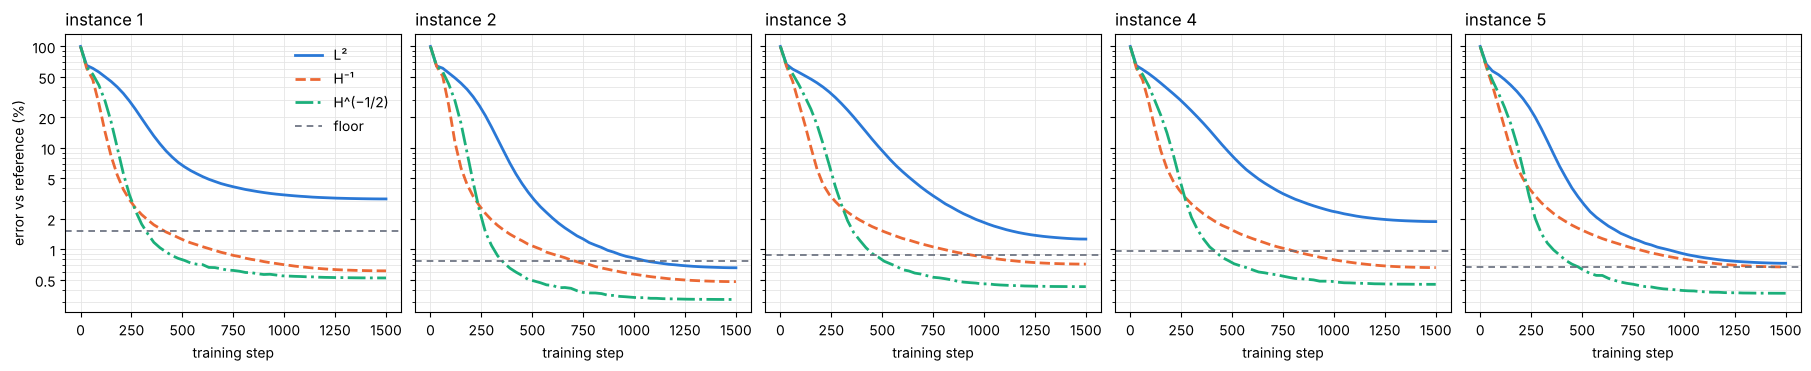

In [6]:
fig = an.plot_scratch_norms(); plt.show()

## Observations

- **Both negative norms beat $L^2$ in all 20 instance comparisons** (15 fine-tuning, 5 from scratch), with the same optimizer, steps and exact minimizer.
- **$H^{-1/2}$ is best in 17 of 20.** The exceptions are all the roughest fine-tuning instance (414, floor 3.6%), where $H^{-1}$ is slightly ahead for every start. This matches the energy-estimate argument for advection-dominated flow.
- **Fine-tuning gains 1.5–1.8×** (mean over instances, depending on the start): smaller than Darcy's 5–7×, and every run stays well above the floor. The norm improves conditioning but does not remove the difficulty of the chaotic solve.
- **From scratch, the gains are larger** ($L^2$ 1.54%, $H^{-1}$ 0.63%, $H^{-1/2}$ 0.42% on average), and both negative norms end *below* the floor on every instance. Since all three losses have the same exact minimizer, this means the network did not reach it: down-weighting the high-frequency residual, where the scheme's own error lives (coarse Crank–Nicolson steps, aliasing), lets the FNO's smooth bias skip that error. A real accuracy gain from implicit regularization, not a better solve of the discrete problem; training much longer would drift back toward the floor.
- **The SOAP-trained operator is the worst starting point for every norm.** In notebook 03 it fit the coarse data grid best but the fine grid worst.
- **Caveats:** one optimizer (SOAP), one learning rate per experiment, 5 instances; the initial-condition weight (5) was not re-tuned for the new norms, so the balance between the two loss terms also changes with $s$.